# Bước 2 — EDA và đặc trưng baseline cho thời gian chờ khám

Notebook dùng target khám V2: KB008 hoặc phòng H401 dùng status 20 cuối trước status 60 đầu; các ca còn lại dùng status 40 cuối trước status 60 đầu. Các bảng và biểu đồ được lưu tại 03_output/step2_eda.

**Cách chạy:** mở notebook bằng kernel Python trong `.venv`, sau đó chọn Restart Kernel and Run All Cells. Nếu notebook đã được mở từ trước khi file được cập nhật, hãy đóng tab và mở lại để nạp code mới nhất. Output của lần chạy kiểm chứng gần nhất đã được lưu trực tiếp trong các cell.

## 1. Thiết lập và đọc dữ liệu

In [1]:
from pathlib import Path
import json
import warnings
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 100)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
sns.set_theme(style='whitegrid', context='notebook')
COLORS = {
    'navy': '#17324D', 'blue': '#2F6690', 'teal': '#3CAEA3',
    'orange': '#F28E2B', 'red': '#D1495B', 'gray': '#6B7280',
    'light': '#E8EEF2',
}

def style_axis(ax, title, xlabel='', ylabel='', grid_axis='y'):
    ax.set_title(title, loc='left', fontsize=14, fontweight='bold', color=COLORS['navy'], pad=12)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.grid(axis=grid_axis, color=COLORS['light'], linewidth=.8)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)

def save_show(fig, filename):
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / filename, dpi=220, bbox_inches='tight', facecolor='white')
    plt.show()

ROOT = Path.cwd().resolve()
if not (ROOT / '03_output').exists():
    ROOT = ROOT.parent
INPUT = ROOT / '03_output' / 'exam_wait_target_v2.csv'
OUTPUT_DIR = ROOT / '03_output' / 'step2_eda'
FIGURE_DIR = OUTPUT_DIR / 'figures'
TABLE_DIR = OUTPUT_DIR / 'tables'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)
assert INPUT.exists(), f'Không tìm thấy input: {INPUT}'

target = pd.read_csv(INPUT, low_memory=False)
for col in ['exam_start_time', 'queue_entry_time', 'first_status20_time', 'latest_status20_before60_time', 'latest_status40_before60_time', 'thoi_gian_chi_dinh']:
    if col in target:
        target[col] = pd.to_datetime(target[col], errors='coerce')
for col in ['waiting_minutes', 'stt', 'phong_thuc_hien_id', 'khoa_thuc_hien_id', 'bac_si_kham_id']:
    if col in target:
        target[col] = pd.to_numeric(target[col], errors='coerce')
for col in ['has_status_20_any', 'has_status_40_any', 'has_status_60_any', 'has_status_40_before_60', 'has_status_20_before_60', 'uses_status20_target', 'required_queue_status_present', 'target_valid_v2', 'cross_day_wait', 'wait_gt_2h', 'wait_gt_4h', 'wait_gt_24h']:
    if col in target and target[col].dtype == 'object':
        target[col] = target[col].astype('string').str.lower().map({'true': True, 'false': False}).fillna(False)

valid = target.loc[target['target_valid_v2']].copy()
print(f'Tất cả dịch vụ: {len(target):,}')
print(f'Target hợp lệ: {len(valid):,} ({len(valid) / len(target):.2%})')
display(target.head(3))

Tất cả dịch vụ: 170,216
Target hợp lệ: 141,519 (83.14%)


,nb_dich_vu_id,nb_dot_dieu_tri_id,dich_vu_id,ma_dich_vu,ten_dich_vu,thoi_gian_chi_dinh,stt,uu_tien,cap_cuu,phong_thuc_hien_id,ma_phong_thuc_hien,ten_phong_thuc_hien,khoa_thuc_hien_id,ma_khoa_thuc_hien,ten_khoa_thuc_hien,bac_si_kham_id,ma_bac_si_kham,exam_start_time,first_status20_time,latest_status20_before60_time,latest_status40_before60_time,has_status_20_any,has_status_40_any,has_status_60_any,has_status_20_before_60,has_status_40_before_60,uses_status20_target,queue_entry_status,target_rule,queue_entry_time,required_queue_status_present,waiting_minutes,target_valid_v2,cross_day_wait,wait_gt_2h,wait_gt_4h,wait_gt_24h,target_issue
0,1456491,294056,8053,KB003,Khám chuyên gia,2026-03-31 21:01:04,4.00,False,False,2102,PK-36,Phòng khám chuyên gia 1 (Giác mạc) A102,161,K30.7,Khám bệnh và điều trị theo yêu cầu,"3,696.00",0101033847,2026-04-01 07:04:28.918,2026-03-31 21:01:04.995,2026-03-31 21:01:04.995,NaT,True,False,True,True,False,False,40,status_40_to_60,NaT,False,NaN,False,False,False,False,False,missing_required_status_40
1,1456490,294057,8053,KB003,Khám chuyên gia,2026-03-31 21:01:04,23.00,False,False,2104,PK-38,Phòng khám chuyên gia 3 (Glôcôm) A104,161,K30.7,Khám bệnh và điều trị theo yêu cầu,"3,733.00",0104014434,2026-04-01 09:12:48.272,2026-03-31 21:01:05.008,2026-03-31 21:01:05.008,2026-04-01 08:42:46.044,True,True,True,True,True,False,40,status_40_to_60,2026-04-01 08:42:46.044,True,30.04,True,False,False,False,False,valid_v2
2,1458888,294059,8053,KB003,Khám chuyên gia,2026-04-01 08:08:02,34.00,False,False,2103,PK-37,Phòng khám chuyên gia 2 A103,161,K30.7,Khám bệnh và điều trị theo yêu cầu,"3,815.00",2696012258,2026-04-01 10:27:32.961,2026-04-01 08:08:02.603,2026-04-01 08:08:02.603,2026-04-01 09:30:31.286,True,True,True,True,True,False,40,status_40_to_60,2026-04-01 09:30:31.286,True,57.03,True,False,False,False,False,valid_v2


## 2. Tổng quan, grain và mức thiếu

In [2]:
overview = pd.DataFrame({
    'metric': ['rows_all', 'unique_service_ids', 'duplicate_service_rows', 'unique_encounters', 'valid_rows', 'valid_rate', 'queue_entry_min', 'queue_entry_max', 'exam_start_min', 'exam_start_max'],
    'value': [len(target), target['nb_dich_vu_id'].nunique(), target['nb_dich_vu_id'].duplicated().sum(), target['nb_dot_dieu_tri_id'].nunique(), len(valid), len(valid) / len(target), valid['queue_entry_time'].min(), valid['queue_entry_time'].max(), valid['exam_start_time'].min(), valid['exam_start_time'].max()],
})
important = ['nb_dich_vu_id', 'nb_dot_dieu_tri_id', 'thoi_gian_chi_dinh', 'queue_entry_time', 'exam_start_time', 'waiting_minutes', 'phong_thuc_hien_id', 'khoa_thuc_hien_id', 'bac_si_kham_id', 'uu_tien', 'cap_cuu']
missing = pd.DataFrame({'column': important, 'missing_count': [target[c].isna().sum() if c in target else len(target) for c in important]})
missing['missing_rate'] = missing['missing_count'] / len(target)
display(overview)
display(missing.sort_values('missing_rate', ascending=False))
overview.to_csv(TABLE_DIR / 'overview.csv', index=False, encoding='utf-8-sig')
missing.to_csv(TABLE_DIR / 'missingness.csv', index=False, encoding='utf-8-sig')

,metric,value
0,rows_all,170216
1,unique_service_ids,170216
2,duplicate_service_rows,0
3,unique_encounters,166349
4,valid_rows,141519
5,valid_rate,0.83
6,queue_entry_min,2026-04-01 05:09:36.585000
7,queue_entry_max,2026-08-04 10:19:34.286000
8,exam_start_min,2026-04-01 05:48:04.909000
9,exam_start_max,2026-08-10 07:52:28.544000


,column,missing_count,missing_rate
3,queue_entry_time,28697,0.17
5,waiting_minutes,28697,0.17
4,exam_start_time,2910,0.02
8,bac_si_kham_id,2381,0.01
2,thoi_gian_chi_dinh,0,0.00
0,nb_dich_vu_id,0,0.00
1,nb_dot_dieu_tri_id,0,0.00
6,phong_thuc_hien_id,0,0.00
7,khoa_thuc_hien_id,0,0.00
9,uu_tien,0,0.00


## 3. Chất lượng target

,quality_group,row_count,rate_of_all_exam
0,valid_review,141396,0.83
1,missing_required_status_40,25787,0.15
2,missing_status_60,2910,0.02
3,cross_day_and_over_24h,77,0.00
4,cross_day,46,0.00


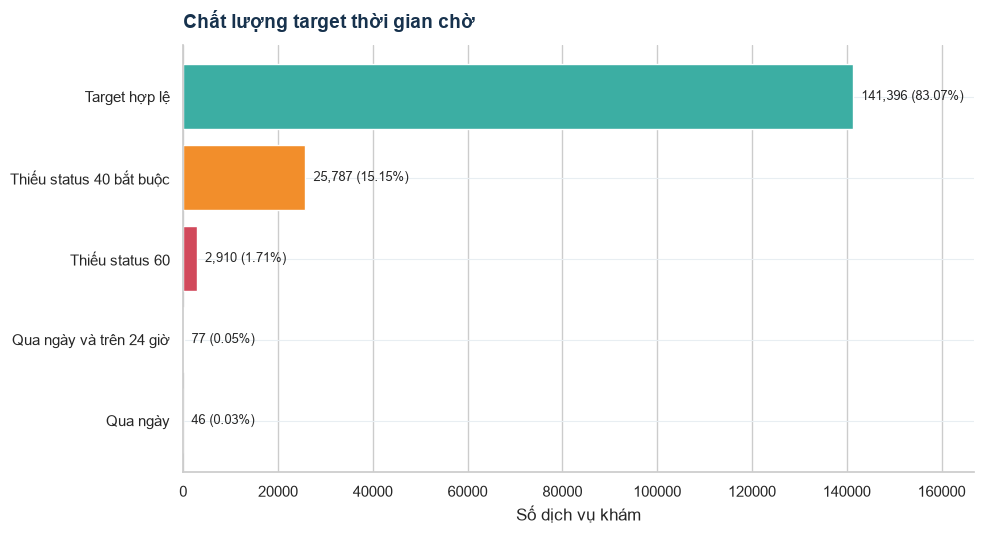

In [3]:
target['quality_group'] = np.select(
    [~target['has_status_60_any'], target['has_status_60_any'] & target['uses_status20_target'] & ~target['has_status_20_before_60'], target['has_status_60_any'] & ~target['uses_status20_target'] & ~target['has_status_40_before_60'], target['waiting_minutes'].lt(0), target['cross_day_wait'] & target['wait_gt_24h'], target['cross_day_wait'], target['wait_gt_24h']],
    ['missing_status_60', 'missing_required_status_20', 'missing_required_status_40', 'negative_wait', 'cross_day_and_over_24h', 'cross_day', 'over_24h'],
    default='valid_review',
)
quality_counts = target['quality_group'].value_counts(dropna=False).rename_axis('quality_group').reset_index(name='row_count')
quality_counts['rate_of_all_exam'] = quality_counts['row_count'] / len(target)
display(quality_counts)
quality_labels = {
    'valid_review': 'Target hợp lệ',
    'missing_required_status_20': 'Thiếu status 20 bắt buộc',
    'missing_required_status_40': 'Thiếu status 40 bắt buộc',
    'missing_status_60': 'Thiếu status 60',
    'cross_day_and_over_24h': 'Qua ngày và trên 24 giờ',
    'cross_day': 'Qua ngày', 'over_24h': 'Trên 24 giờ', 'negative_wait': 'Thời gian âm',
}
quality_plot = quality_counts.assign(label=quality_counts['quality_group'].map(quality_labels))
fig, ax = plt.subplots(figsize=(10, 5.5))
quality_color_map = {'valid_review': COLORS['teal'], 'missing_required_status_20': COLORS['orange'], 'missing_required_status_40': COLORS['orange'], 'missing_status_60': COLORS['red'], 'cross_day_and_over_24h': COLORS['navy'], 'cross_day': COLORS['gray'], 'over_24h': COLORS['navy'], 'negative_wait': COLORS['red']}
bars = ax.barh(quality_plot['label'], quality_plot['row_count'], color=quality_plot['quality_group'].map(quality_color_map))
ax.invert_yaxis()
for bar, count, rate in zip(bars, quality_plot['row_count'], quality_plot['rate_of_all_exam']):
    ax.text(bar.get_width(), bar.get_y() + bar.get_height() / 2, f'  {count:,} ({rate:.2%})', va='center', fontsize=9)
style_axis(ax, 'Chất lượng target thời gian chờ', 'Số dịch vụ khám', '')
ax.margins(x=.18)
save_show(fig, '01_target_quality.png')
quality_counts.to_csv(TABLE_DIR / 'quality_groups.csv', index=False, encoding='utf-8-sig')

## 4. Phân phối thời gian chờ

,quantile,waiting_minutes
0,0.00,0.00
1,0.01,0.41
2,0.05,2.13
3,0.25,7.91
4,0.50,15.82
5,0.75,28.18
6,0.90,48.10
7,0.95,66.18
8,0.99,135.09
9,1.00,"47,144.08"


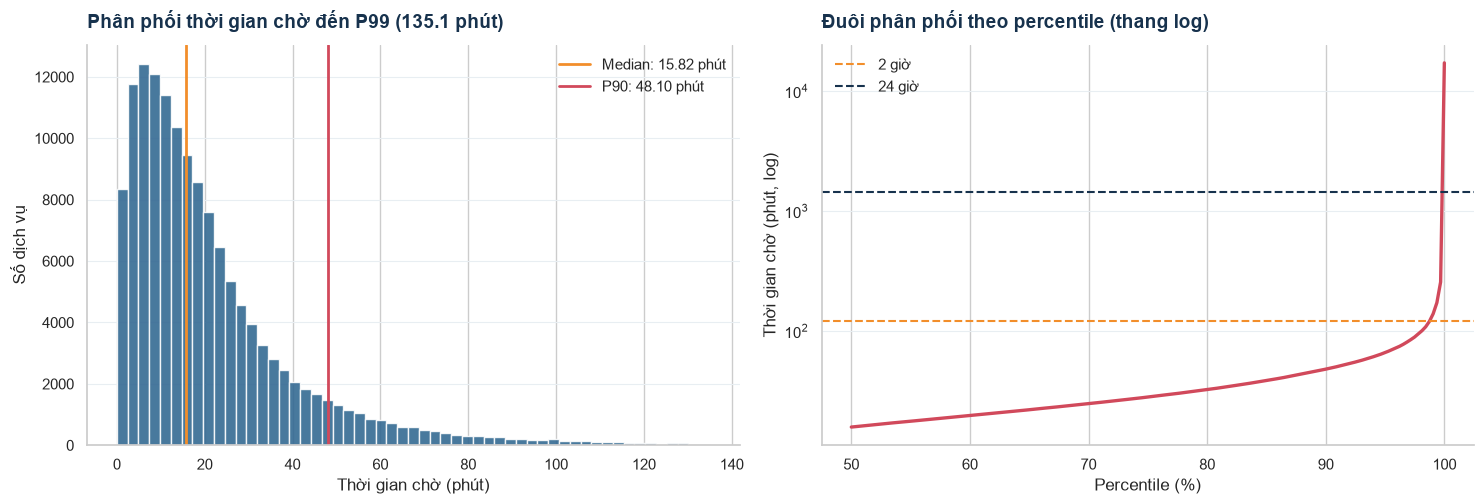

In [4]:
levels = [0, .01, .05, .25, .50, .75, .90, .95, .99, 1]
quantiles = valid['waiting_minutes'].quantile(levels).rename_axis('quantile').reset_index(name='waiting_minutes')
display(quantiles)
values = valid['waiting_minutes'].dropna()
median, p90, p99 = values.median(), values.quantile(.90), values.quantile(.99)
shown = values.loc[values.le(p99)]  # Lọc khi hiển thị, không clip để tránh dồn giả ở cột cuối.
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
axes[0].hist(shown, bins=55, color=COLORS['blue'], alpha=.88, edgecolor='white')
axes[0].axvline(median, color=COLORS['orange'], linewidth=2, label=f'Median: {median:.2f} phút')
axes[0].axvline(p90, color=COLORS['red'], linewidth=2, label=f'P90: {p90:.2f} phút')
style_axis(axes[0], f'Phân phối thời gian chờ đến P99 ({p99:.1f} phút)', 'Thời gian chờ (phút)', 'Số dịch vụ')
axes[0].legend(frameon=False)

percentiles = np.linspace(.50, .9999, 160)
tail = values.quantile(percentiles)
axes[1].plot(percentiles * 100, tail, color=COLORS['red'], linewidth=2.4)
axes[1].axhline(120, color=COLORS['orange'], linestyle='--', label='2 giờ')
axes[1].axhline(1440, color=COLORS['navy'], linestyle='--', label='24 giờ')
axes[1].set_yscale('log')
style_axis(axes[1], 'Đuôi phân phối theo percentile (thang log)', 'Percentile (%)', 'Thời gian chờ (phút, log)')
axes[1].legend(frameon=False)
save_show(fig, '02_waiting_distribution_and_tail.png')
quantiles.to_csv(TABLE_DIR / 'waiting_quantiles.csv', index=False, encoding='utf-8-sig')

## 5. Chiều thời gian và hàm tổng hợp

In [5]:
DAY_NAMES = {0: 'Thứ 2', 1: 'Thứ 3', 2: 'Thứ 4', 3: 'Thứ 5', 4: 'Thứ 6', 5: 'Thứ 7', 6: 'Chủ nhật'}
qtime = valid['queue_entry_time']
valid['queue_entry_date'] = qtime.dt.floor('D')
valid['queue_entry_hour'] = qtime.dt.hour.astype('Int64')
valid['queue_entry_day_of_week'] = qtime.dt.dayofweek.astype('Int64')
valid['queue_entry_day_name'] = valid['queue_entry_day_of_week'].map(DAY_NAMES)
valid['queue_entry_is_weekend'] = qtime.dt.dayofweek.ge(5).astype('Int64')
valid['queue_entry_month'] = qtime.dt.to_period('M').astype('string')
valid['order_to_queue_minutes'] = (qtime - valid['thoi_gian_chi_dinh']).dt.total_seconds().div(60)

def grouped_waiting(frame, columns, minimum_rows=30):
    out = frame.groupby(columns, dropna=False).agg(exam_count=('nb_dich_vu_id', 'size'), median_waiting_minutes=('waiting_minutes', 'median'), p90_waiting_minutes=('waiting_minutes', lambda x: x.quantile(.90)), p95_waiting_minutes=('waiting_minutes', lambda x: x.quantile(.95)), mean_waiting_minutes=('waiting_minutes', 'mean'), over_2h_count=('wait_gt_2h', 'sum')).reset_index()
    out['over_2h_rate'] = out['over_2h_count'] / out['exam_count']
    return out.loc[out['exam_count'].ge(minimum_rows)].sort_values(['median_waiting_minutes', 'exam_count'], ascending=[False, False])

## 6. EDA theo giờ, thứ và ngày

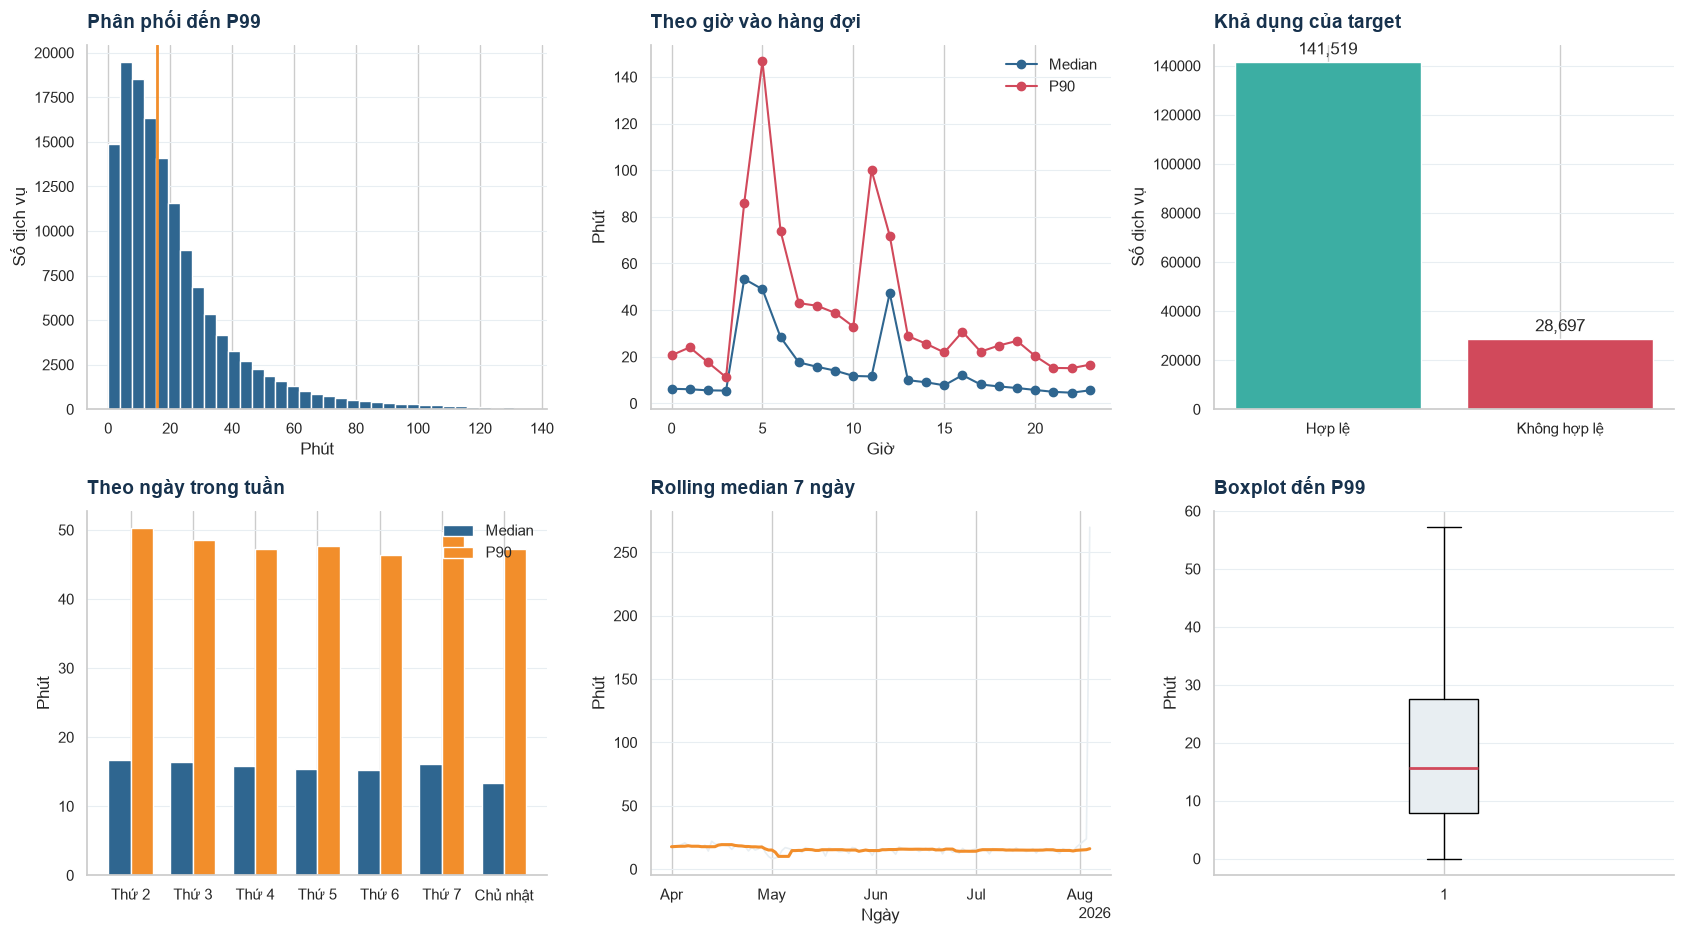

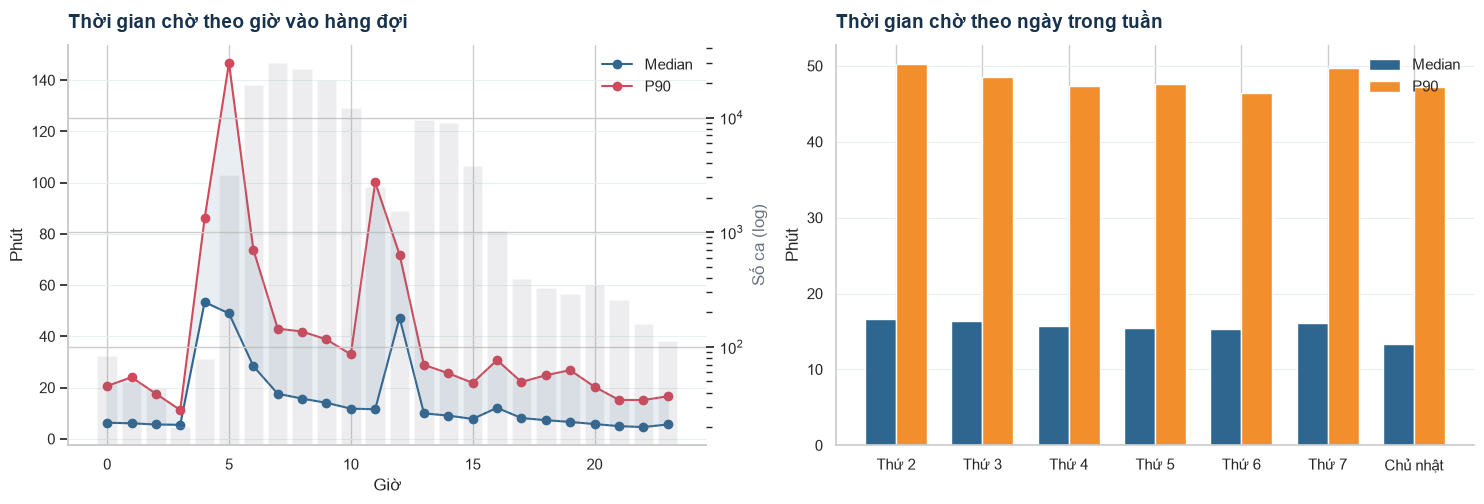

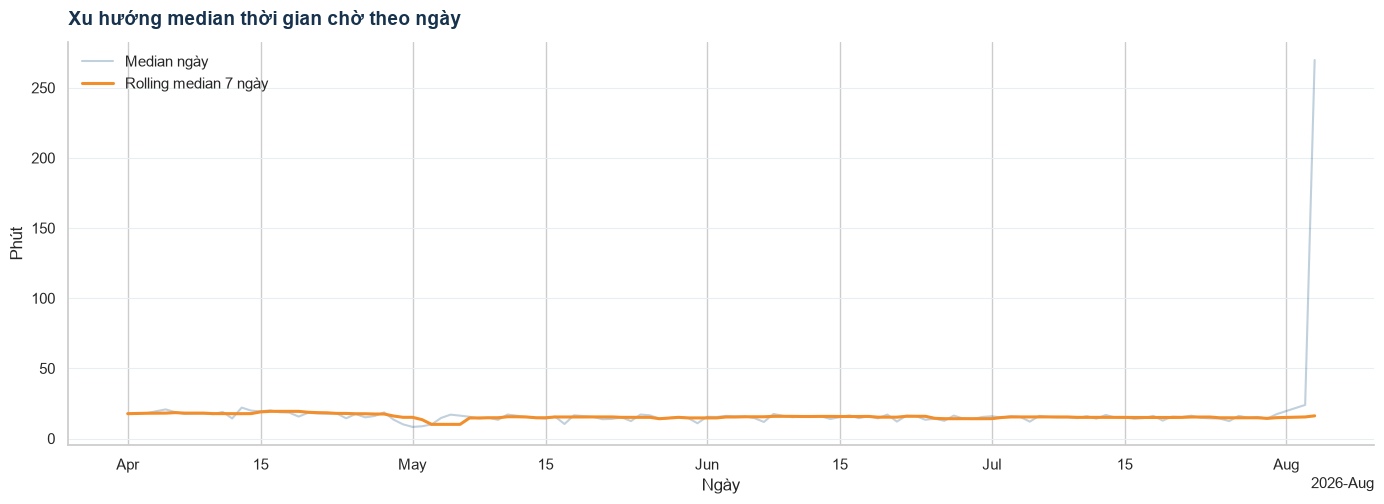

In [6]:
by_hour = grouped_waiting(valid, ['queue_entry_hour'], 1).sort_values('queue_entry_hour')
by_day = grouped_waiting(valid, ['queue_entry_day_of_week', 'queue_entry_day_name'], 1).sort_values('queue_entry_day_of_week')
daily = valid.groupby('queue_entry_date').agg(exam_count=('nb_dich_vu_id', 'size'), median_waiting_minutes=('waiting_minutes', 'median'), p90_waiting_minutes=('waiting_minutes', lambda x: x.quantile(.90))).reset_index().sort_values('queue_entry_date')
daily['median_7d'] = daily['median_waiting_minutes'].rolling(7, min_periods=1).median()

# Dashboard tóm tắt để dùng trực tiếp trong báo cáo/luận văn.
fig, axes = plt.subplots(2, 3, figsize=(17, 9.5))
axes[0, 0].hist(shown, bins=35, color=COLORS['blue'], edgecolor='white')
axes[0, 0].axvline(median, color=COLORS['orange'], linewidth=2)
style_axis(axes[0, 0], 'Phân phối đến P99', 'Phút', 'Số dịch vụ')
axes[0, 1].plot(by_hour['queue_entry_hour'], by_hour['median_waiting_minutes'], marker='o', color=COLORS['blue'], label='Median')
axes[0, 1].plot(by_hour['queue_entry_hour'], by_hour['p90_waiting_minutes'], marker='o', color=COLORS['red'], label='P90')
style_axis(axes[0, 1], 'Theo giờ vào hàng đợi', 'Giờ', 'Phút'); axes[0, 1].legend(frameon=False)
validity = target['target_valid_v2'].value_counts().reindex([True, False], fill_value=0)
bars = axes[0, 2].bar(['Hợp lệ', 'Không hợp lệ'], validity.values, color=[COLORS['teal'], COLORS['red']])
axes[0, 2].bar_label(bars, labels=[f'{v:,}' for v in validity.values], padding=3)
style_axis(axes[0, 2], 'Khả dụng của target', '', 'Số dịch vụ')
x = np.arange(len(by_day)); width = .36
axes[1, 0].bar(x - width / 2, by_day['median_waiting_minutes'], width, color=COLORS['blue'], label='Median')
axes[1, 0].bar(x + width / 2, by_day['p90_waiting_minutes'], width, color=COLORS['orange'], label='P90')
axes[1, 0].set_xticks(x, by_day['queue_entry_day_name'])
style_axis(axes[1, 0], 'Theo ngày trong tuần', '', 'Phút'); axes[1, 0].legend(frameon=False)
axes[1, 1].plot(daily['queue_entry_date'], daily['median_waiting_minutes'], color=COLORS['light'], linewidth=1.2)
axes[1, 1].plot(daily['queue_entry_date'], daily['median_7d'], color=COLORS['orange'], linewidth=2.2)
dashboard_locator = mdates.AutoDateLocator(minticks=3, maxticks=5)
axes[1, 1].xaxis.set_major_locator(dashboard_locator)
axes[1, 1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(dashboard_locator))
style_axis(axes[1, 1], 'Rolling median 7 ngày', 'Ngày', 'Phút')
axes[1, 2].boxplot(shown, orientation='vertical', showfliers=False, patch_artist=True, boxprops={'facecolor': COLORS['light']}, medianprops={'color': COLORS['red'], 'linewidth': 2})
style_axis(axes[1, 2], 'Boxplot đến P99', '', 'Phút')
save_show(fig, '00_eda_dashboard.png')

fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
axes[0].plot(by_hour['queue_entry_hour'], by_hour['median_waiting_minutes'], marker='o', color=COLORS['blue'], label='Median')
axes[0].plot(by_hour['queue_entry_hour'], by_hour['p90_waiting_minutes'], marker='o', color=COLORS['red'], label='P90')
axes[0].fill_between(by_hour['queue_entry_hour'].astype(float), by_hour['median_waiting_minutes'], by_hour['p90_waiting_minutes'], color=COLORS['light'])
style_axis(axes[0], 'Thời gian chờ theo giờ vào hàng đợi', 'Giờ', 'Phút'); axes[0].legend(frameon=False)
hour_volume_ax = axes[0].twinx()
hour_volume_ax.bar(by_hour['queue_entry_hour'], by_hour['exam_count'], color=COLORS['gray'], alpha=.12, width=.8)
hour_volume_ax.set_yscale('log'); hour_volume_ax.set_ylabel('Số ca (log)', color=COLORS['gray'])
hour_volume_ax.spines[['top', 'right']].set_visible(False)
axes[1].bar(x - width / 2, by_day['median_waiting_minutes'], width, color=COLORS['blue'], label='Median')
axes[1].bar(x + width / 2, by_day['p90_waiting_minutes'], width, color=COLORS['orange'], label='P90')
axes[1].set_xticks(x, by_day['queue_entry_day_name'])
style_axis(axes[1], 'Thời gian chờ theo ngày trong tuần', '', 'Phút'); axes[1].legend(frameon=False)
save_show(fig, '03_waiting_by_hour_weekday.png')

fig, ax = plt.subplots(figsize=(14, 5.2))
ax.plot(daily['queue_entry_date'], daily['median_waiting_minutes'], color=COLORS['blue'], alpha=.3, label='Median ngày')
ax.plot(daily['queue_entry_date'], daily['median_7d'], color=COLORS['orange'], linewidth=2.2, label='Rolling median 7 ngày')
trend_locator = mdates.AutoDateLocator(minticks=5, maxticks=9)
ax.xaxis.set_major_locator(trend_locator); ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(trend_locator))
style_axis(ax, 'Xu hướng median thời gian chờ theo ngày', 'Ngày', 'Phút'); ax.legend(frameon=False)
save_show(fig, '04_daily_trend.png')
by_hour.to_csv(TABLE_DIR / 'waiting_by_hour.csv', index=False, encoding='utf-8-sig')
by_day.to_csv(TABLE_DIR / 'waiting_by_day.csv', index=False, encoding='utf-8-sig')
daily.to_csv(TABLE_DIR / 'waiting_daily.csv', index=False, encoding='utf-8-sig')

## 7. Phòng, khoa, bác sĩ, dịch vụ và ưu tiên

Nguồn chưa có tên bác sĩ. Phần phân tích bác sĩ sử dụng `bac_si_kham_id` và `ma_bac_si_kham`; các nhóm còn lại ưu tiên hiển thị tên.

,ten_phong_thuc_hien,exam_count,median_waiting_minutes,p90_waiting_minutes,p95_waiting_minutes,mean_waiting_minutes,over_2h_count,over_2h_rate
22,Khám nội H401,2525,46.42,176.23,255.81,210.75,430,0.17
36,Phòng khám Nội E1108,373,31.88,88.37,130.13,99.98,24,0.06
48,Phòng khám ngoại trú C502A,1072,30.23,101.85,121.78,44.19,57,0.05
59,Phòng khám số 19 (BHYT),88,28.15,69.53,82.66,37.79,3,0.03
41,Phòng khám chuyên gia 5 (MTE) A106,1855,27.93,119.91,177.00,48.36,185,0.10
39,Phòng khám chuyên gia 3 (Glôcôm) A104,2147,27.88,75.38,147.06,40.21,155,0.07
38,Phòng khám chuyên gia 2 A103,3396,26.94,85.69,435.83,60.16,244,0.07
77,THTM mắt và vùng mặt E803,434,26.33,75.15,99.02,103.48,9,0.02
37,Phòng khám chuyên gia 1 (Giác mạc) A102,2156,24.35,68.15,99.62,35.16,80,0.04
31,Phòng khám 2 E1101,691,23.40,71.96,85.08,37.05,16,0.02


,ten_khoa_thuc_hien,exam_count,median_waiting_minutes,p90_waiting_minutes,p95_waiting_minutes,mean_waiting_minutes,over_2h_count,over_2h_rate
4,Glôcôm,1406,27.55,96.27,112.98,40.07,60,0.04
8,Mắt trẻ em,2150,19.95,91.08,109.74,42.13,78,0.04
9,Tạo hình - Thẩm mỹ mắt và vùng mặt,2090,18.32,58.26,81.14,63.62,29,0.01
6,Khám bệnh và điều trị theo yêu cầu,108367,16.43,46.74,62.06,27.16,1284,0.01
0,Chấn thương mắt,3322,16.42,95.28,120.21,38.34,169,0.05
7,Khúc xạ,10772,14.16,35.35,46.96,42.20,27,0.00
3,Giác mạc,3971,12.55,62.52,83.22,22.74,46,0.01
5,Khám bệnh và điều trị ngoại trú,4449,10.35,37.99,52.43,16.61,19,0.00
2,Dịch kính - Võng mạc,4984,10.02,64.03,83.42,35.53,91,0.02


,bac_si_kham_id,ma_bac_si_kham,exam_count,median_waiting_minutes,p90_waiting_minutes,p95_waiting_minutes,mean_waiting_minutes,over_2h_count,over_2h_rate
128,"3,997.00",0303005622,384,66.88,217.41,272.86,253.51,94,0.24
134,"4,030.00",0115037656,372,48.51,177.72,250.33,264.15,73,0.20
133,"4,025.00",0115072803,469,44.58,171.17,249.40,239.44,69,0.15
130,"4,014.00",0110175947,346,44.24,155.08,198.66,97.35,59,0.17
131,"4,018.00",0107072101,460,43.75,188.55,257.82,196.83,77,0.17
132,"4,020.00",0111086964,446,36.97,131.10,236.36,169.98,51,0.11
118,"3,911.00",9716600336,40,33.45,125.55,"1,987.38",585.79,4,0.10
97,"3,821.00",0111005236,450,31.84,95.30,226.10,58.07,32,0.07
93,"3,815.00",2696012258,240,29.99,431.69,467.05,124.56,34,0.14
68,"3,753.00",0105050510,425,29.64,85.34,148.09,41.24,30,0.07


,ten_dich_vu,exam_count,median_waiting_minutes,p90_waiting_minutes,p95_waiting_minutes,mean_waiting_minutes,over_2h_count,over_2h_rate
7,Khám nội khoa,2898,43.37,164.32,244.13,196.49,454,0.16
3,Khám chuyên gia,15889,25.05,65.05,111.37,39.89,729,0.05
5,Khám mắt,5846,15.33,54.37,71.25,24.48,98,0.02
2,Khám bệnh trong giờ hành chính,84201,14.51,39.81,51.25,22.24,132,0.00
0,Khám bệnh chuyên sâu,12117,14.23,83.13,104.79,42.94,369,0.03
1,Khám bệnh ngoài giờ hành chính,20490,13.78,44.54,59.80,19.30,21,0.00
6,Khám người nước ngoài,70,11.03,29.87,66.31,17.66,0,0.00


,nhom_uu_tien,exam_count,median_waiting_minutes,p90_waiting_minutes,p95_waiting_minutes,mean_waiting_minutes,over_2h_count,over_2h_rate
0,Thông thường,121677,15.36,44.90,61.26,28.44,1225,0.01
1,Ưu tiên,19842,19.99,66.33,92.18,34.58,579,0.03


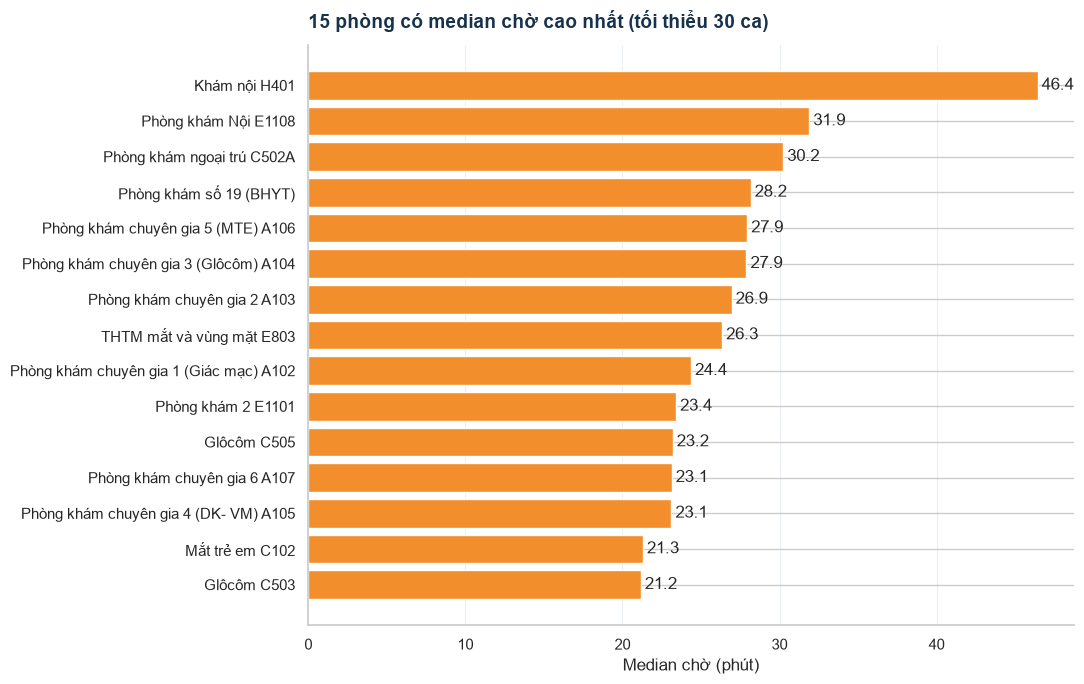

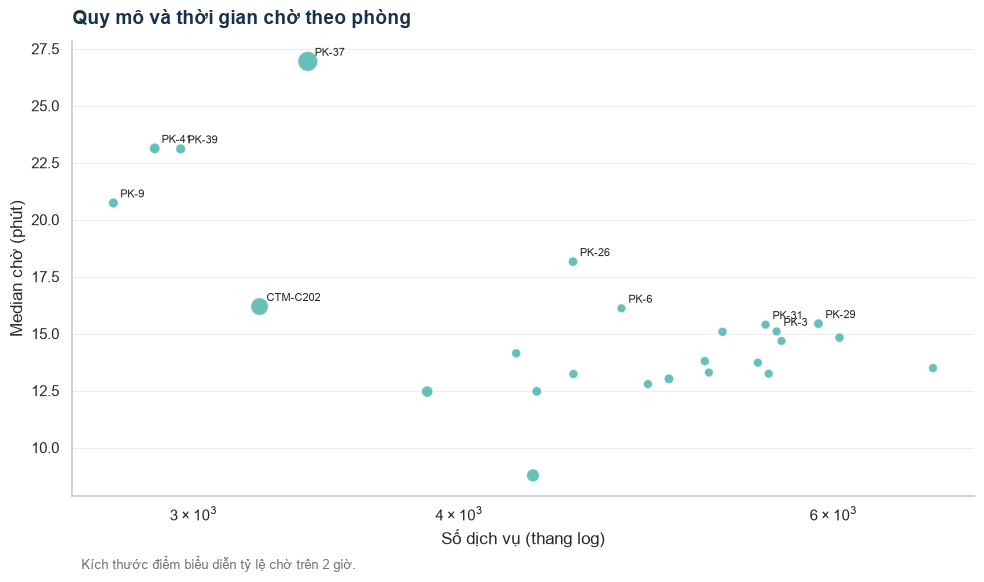

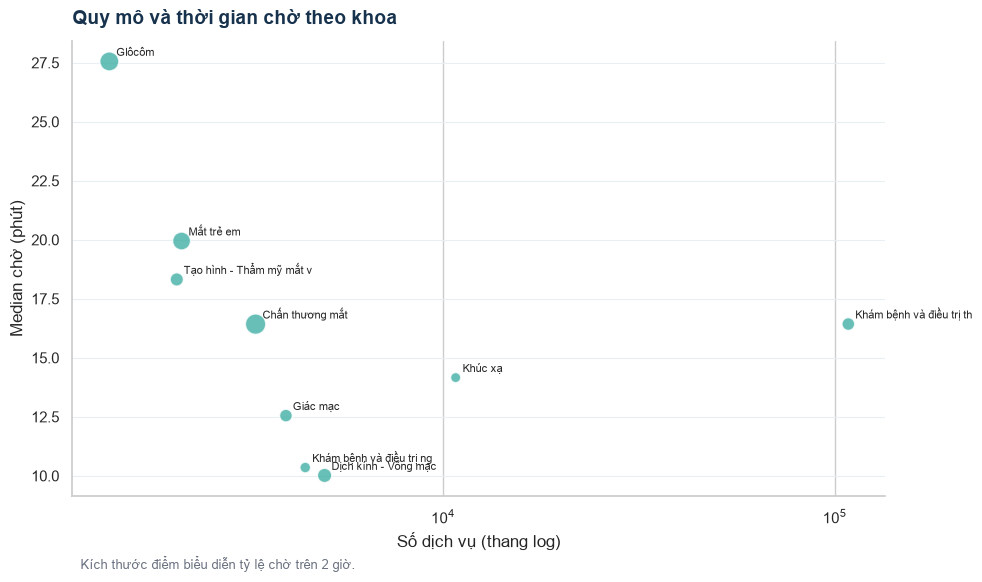

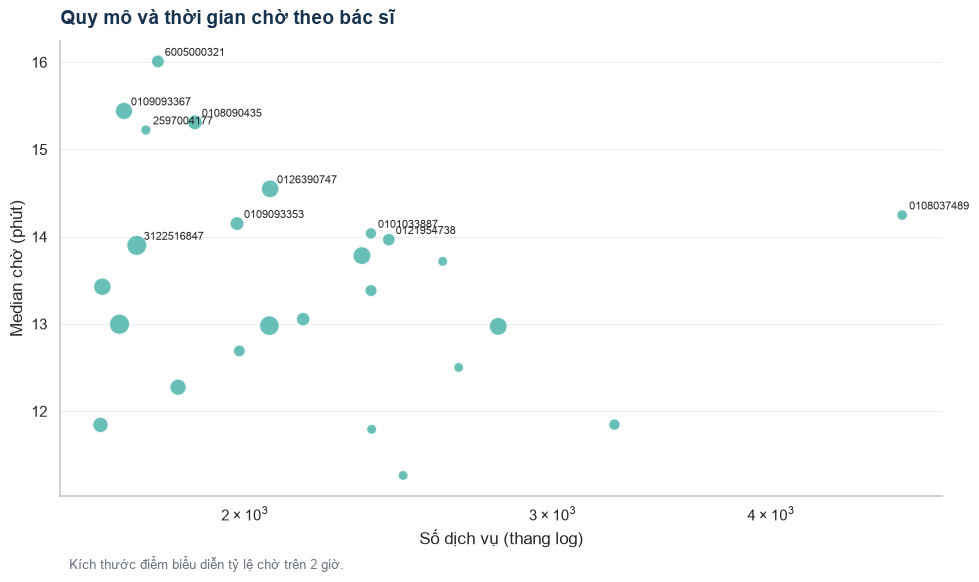

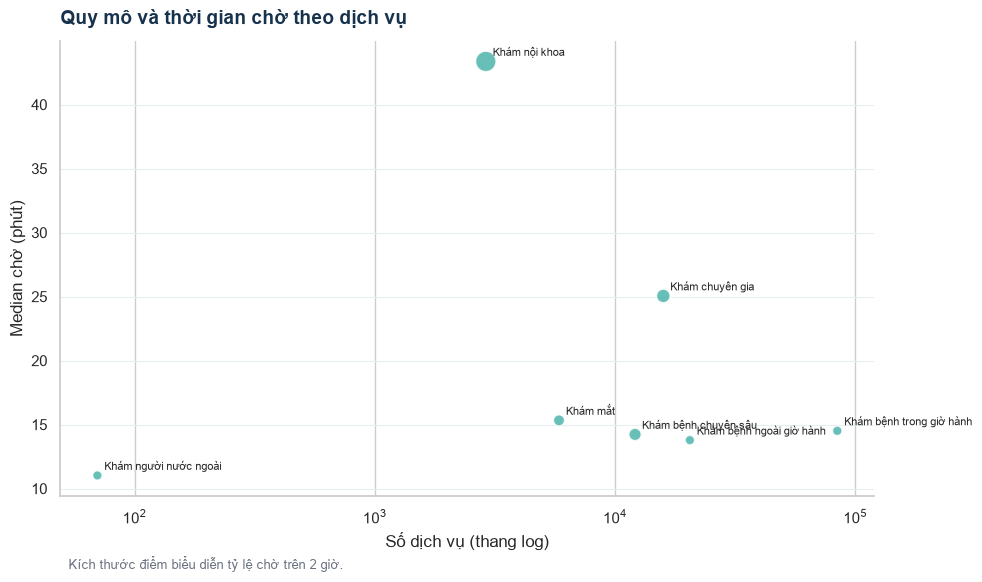

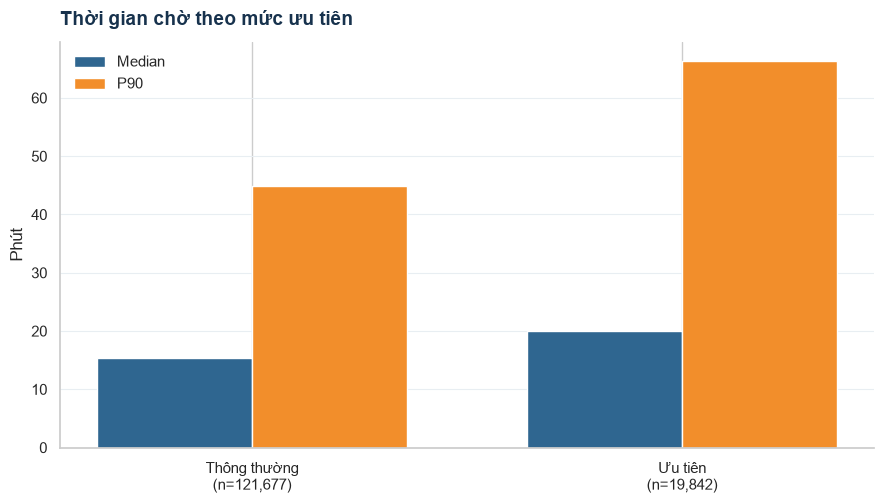

In [7]:
by_room = grouped_waiting(valid, ['ten_phong_thuc_hien'])
by_room_code = grouped_waiting(valid, ['ma_phong_thuc_hien'])
by_department = grouped_waiting(valid, ['ten_khoa_thuc_hien'])
by_doctor = grouped_waiting(valid, ['bac_si_kham_id', 'ma_bac_si_kham'])
by_service = grouped_waiting(valid, ['ten_dich_vu'])
by_priority = grouped_waiting(valid, ['uu_tien', 'cap_cuu'], 1)
priority_plot = by_priority.sort_values(['uu_tien', 'cap_cuu']).copy()
priority_plot['nhom_uu_tien'] = np.select([priority_plot['cap_cuu'], priority_plot['uu_tien']], ['Cấp cứu', 'Ưu tiên'], default='Thông thường')
priority_named = priority_plot[['nhom_uu_tien', 'exam_count', 'median_waiting_minutes', 'p90_waiting_minutes', 'p95_waiting_minutes', 'mean_waiting_minutes', 'over_2h_count', 'over_2h_rate']]
display(by_room.head(15)); display(by_department); display(by_doctor.head(15)); display(by_service); display(priority_named)

plot_data = by_room.head(15).sort_values('median_waiting_minutes')
fig, ax = plt.subplots(figsize=(11, 7))
bars = ax.barh(plot_data['ten_phong_thuc_hien'], plot_data['median_waiting_minutes'], color=COLORS['orange'])
ax.bar_label(bars, labels=[f'{value:.1f}' for value in plot_data['median_waiting_minutes']], padding=3)
style_axis(ax, '15 phòng có median chờ cao nhất (tối thiểu 30 ca)', 'Median chờ (phút)', '', grid_axis='x')
save_show(fig, '05_top_rooms.png')

# So sánh quy mô và median giúp tránh diễn giải nhóm ít ca như một vấn đề vận hành lớn.
def volume_wait_scatter(table, label_column, title, filename, top_n=25):
    plot = table.nlargest(top_n, 'exam_count').copy()
    fig, ax = plt.subplots(figsize=(10, 6))
    sizes = 45 + 170 * (plot['over_2h_rate'] / max(plot['over_2h_rate'].max(), .001))
    ax.scatter(plot['exam_count'], plot['median_waiting_minutes'], s=sizes, color=COLORS['teal'], alpha=.78, edgecolors='white')
    for row in plot.nlargest(10, 'median_waiting_minutes').itertuples(index=False):
        ax.annotate(str(getattr(row, label_column))[:24], (row.exam_count, row.median_waiting_minutes), xytext=(5, 4), textcoords='offset points', fontsize=8)
    ax.set_xscale('log')
    style_axis(ax, title, 'Số dịch vụ (thang log)', 'Median chờ (phút)')
    ax.text(.01, -.16, 'Kích thước điểm biểu diễn tỷ lệ chờ trên 2 giờ.', transform=ax.transAxes, fontsize=9, color=COLORS['gray'])
    save_show(fig, filename)

volume_wait_scatter(by_room_code, 'ma_phong_thuc_hien', 'Quy mô và thời gian chờ theo phòng', '06_room_volume_vs_wait.png')
volume_wait_scatter(by_department, 'ten_khoa_thuc_hien', 'Quy mô và thời gian chờ theo khoa', '07_department_volume_vs_wait.png', top_n=20)
volume_wait_scatter(by_doctor.dropna(subset=['ma_bac_si_kham']), 'ma_bac_si_kham', 'Quy mô và thời gian chờ theo bác sĩ', '08_doctor_volume_vs_wait.png')
volume_wait_scatter(by_service, 'ten_dich_vu', 'Quy mô và thời gian chờ theo dịch vụ', '09_service_volume_vs_wait.png', top_n=20)

x_priority = np.arange(len(priority_plot)); width_priority = .36
fig, ax = plt.subplots(figsize=(9, 5.2))
ax.bar(x_priority - width_priority / 2, priority_plot['median_waiting_minutes'], width_priority, color=COLORS['blue'], label='Median')
ax.bar(x_priority + width_priority / 2, priority_plot['p90_waiting_minutes'], width_priority, color=COLORS['orange'], label='P90')
ax.set_xticks(x_priority, [f'{label}\n(n={count:,})' for label, count in zip(priority_plot['nhom_uu_tien'], priority_plot['exam_count'])])
style_axis(ax, 'Thời gian chờ theo mức ưu tiên', '', 'Phút'); ax.legend(frameon=False)
save_show(fig, '10_waiting_by_priority.png')
for name, table in {'room': by_room, 'department': by_department, 'doctor': by_doctor, 'service': by_service, 'priority': priority_named}.items():
    table.to_csv(TABLE_DIR / f'waiting_by_{name}.csv', index=False, encoding='utf-8-sig')

## 8. Ngoại lệ cần rà soát

In [8]:
outlier_cols = ['nb_dich_vu_id', 'nb_dot_dieu_tri_id', 'ma_dich_vu', 'ten_dich_vu', 'target_rule', 'queue_entry_status', 'queue_entry_time', 'exam_start_time', 'waiting_minutes', 'phong_thuc_hien_id', 'ma_phong_thuc_hien', 'bac_si_kham_id', 'cross_day_wait', 'wait_gt_2h', 'wait_gt_4h', 'wait_gt_24h']
top_outliers = valid.sort_values('waiting_minutes', ascending=False)[outlier_cols].head(100)
over_24h = valid.loc[valid['wait_gt_24h'], outlier_cols].sort_values('waiting_minutes', ascending=False)
missing_required_queue_status = target.loc[target['has_status_60_any'] & ~target['required_queue_status_present']].copy()
missing_40_with_20 = target.loc[target['has_status_60_any'] & ~target['uses_status20_target'] & ~target['has_status_40_before_60'] & target['has_status_20_before_60']].copy()
print(f'Chờ trên 24 giờ: {len(over_24h):,}')
print(f'Chờ qua ngày: {int(valid["cross_day_wait"].sum()):,}')
print(f'Thiếu trạng thái hàng đợi bắt buộc theo quy tắc V2: {len(missing_required_queue_status):,}')
display(top_outliers.head(20))

# Phân tích độ nhạy: outlier ảnh hưởng mạnh đến mean nhưng ít ảnh hưởng median.
sensitivity_rows = []
for label, upper in [('Toàn bộ valid', np.inf), ('Không quá 24 giờ', 1440), ('Không quá 4 giờ', 240), ('Không quá 2 giờ', 120)]:
    sample = valid.loc[valid['waiting_minutes'].le(upper)]
    sensitivity_rows.append({
        'scenario': label, 'retained_rows': len(sample), 'retained_rate': len(sample) / len(valid),
        'mean_minutes': sample['waiting_minutes'].mean(), 'median_minutes': sample['waiting_minutes'].median(),
        'p95_minutes': sample['waiting_minutes'].quantile(.95),
    })
outlier_sensitivity = pd.DataFrame(sensitivity_rows)
display(outlier_sensitivity)
top_outliers.to_csv(TABLE_DIR / 'top_100_waiting_outliers.csv', index=False, encoding='utf-8-sig')
over_24h.to_csv(TABLE_DIR / 'waiting_over_24h.csv', index=False, encoding='utf-8-sig')
missing_required_queue_status.to_csv(TABLE_DIR / 'missing_required_queue_status.csv', index=False, encoding='utf-8-sig')
missing_40_with_20.to_csv(TABLE_DIR / 'missing_40_with_status20_before60.csv', index=False, encoding='utf-8-sig')
outlier_sensitivity.to_csv(TABLE_DIR / 'outlier_sensitivity.csv', index=False, encoding='utf-8-sig')

Chờ trên 24 giờ: 77
Chờ qua ngày: 123
Thiếu trạng thái hàng đợi bắt buộc theo quy tắc V2: 25,787


,nb_dich_vu_id,nb_dot_dieu_tri_id,ma_dich_vu,ten_dich_vu,target_rule,queue_entry_status,queue_entry_time,exam_start_time,waiting_minutes,phong_thuc_hien_id,ma_phong_thuc_hien,bac_si_kham_id,cross_day_wait,wait_gt_2h,wait_gt_4h,wait_gt_24h
32063,1822348,332568,KB006,Khám bệnh chuyên sâu,status_40_to_60,40,2026-04-24 15:20:59.284,2026-05-27 09:05:03.920,"47,144.08",2088,PK-22,"3,829.00",True,True,True,True
76031,2320181,386579,KB004,Khám bệnh trong giờ hành chính,status_40_to_60,40,2026-06-02 08:25:22.681,2026-07-03 18:28:39.691,"45,243.28",2079,PK-13,NaN,True,True,True,True
76070,2320687,386633,KB004,Khám bệnh trong giờ hành chính,status_40_to_60,40,2026-06-02 08:49:37.545,2026-07-03 18:29:02.077,"45,219.41",2079,PK-13,NaN,True,True,True,True
80943,2384205,392642,KB004,Khám bệnh trong giờ hành chính,status_40_to_60,40,2026-06-05 07:53:37.530,2026-07-03 18:28:26.138,"40,954.81",2079,PK-13,NaN,True,True,True,True
135429,2969307,458569,KB004,Khám bệnh trong giờ hành chính,status_40_to_60,40,2026-07-10 07:31:02.565,2026-08-06 18:00:02.203,"39,508.99",2079,PK-13,NaN,True,True,True,True
6559,1522496,301978,KB006,Khám bệnh chuyên sâu,status_40_to_60,40,2026-04-06 08:43:27.921,2026-04-26 16:24:05.404,"29,260.62",2122,THTM-E803B,"3,954.00",True,True,True,True
147847,3106163,474036,KB004,Khám bệnh trong giờ hành chính,status_40_to_60,40,2026-07-17 13:54:02.409,2026-08-06 18:00:10.793,"29,046.14",2079,PK-13,NaN,True,True,True,True
155671,3228033,483596,KB008,Khám nội khoa,status_20_to_60,20,2026-07-24 14:41:42.783,2026-08-10 07:52:28.544,"24,070.76",2322,H401,"4,020.00",True,True,True,True
58842,2124154,365148,KB008,Khám nội khoa,status_20_to_60,20,2026-05-19 10:25:01.783,2026-06-04 08:39:18.230,"22,934.27",2322,H401,"4,030.00",True,True,True,True
154651,3169727,482346,KB004,Khám bệnh trong giờ hành chính,status_40_to_60,40,2026-07-22 07:36:27.146,2026-08-06 17:59:53.392,"22,223.44",2079,PK-13,NaN,True,True,True,True


,scenario,retained_rows,retained_rate,mean_minutes,median_minutes,p95_minutes
0,Toàn bộ valid,141519,1.00,29.30,15.82,66.18
1,Không quá 24 giờ,141442,1.00,23.50,15.81,65.84
2,Không quá 4 giờ,141013,1.00,22.22,15.75,64.23
3,Không quá 2 giờ,139715,0.99,20.95,15.58,60.10


## 9. Bộ đặc trưng baseline

Không đưa exam_start_time, trạng thái sau khi bắt đầu khám hoặc trường kết luận vào feature. waiting_minutes chỉ được thêm vào model dataset với vai trò target.

In [9]:
feature_cols = ['nb_dich_vu_id', 'nb_dot_dieu_tri_id', 'dich_vu_id', 'ma_dich_vu', 'ten_dich_vu', 'phong_thuc_hien_id', 'ma_phong_thuc_hien', 'khoa_thuc_hien_id', 'ma_khoa_thuc_hien', 'bac_si_kham_id', 'ma_bac_si_kham', 'stt', 'uu_tien', 'cap_cuu', 'queue_entry_status', 'thoi_gian_chi_dinh', 'queue_entry_time', 'queue_entry_date', 'queue_entry_hour', 'queue_entry_day_of_week', 'queue_entry_is_weekend', 'queue_entry_month', 'order_to_queue_minutes']
feature_cols = [c for c in feature_cols if c in valid]
features = valid[feature_cols].copy()
model_dataset = features.copy()
model_dataset['waiting_minutes'] = valid['waiting_minutes'].to_numpy()
assert model_dataset['nb_dich_vu_id'].is_unique
assert model_dataset['waiting_minutes'].ge(0).all()
features.to_csv(OUTPUT_DIR / 'step2_baseline_features.csv', index=False, encoding='utf-8-sig')
model_dataset.to_csv(OUTPUT_DIR / 'step2_model_dataset.csv', index=False, encoding='utf-8-sig')
print(f'Đã xuất {len(model_dataset):,} dòng, {len(feature_cols)} feature columns và một target.')
display(model_dataset.head())

Đã xuất 141,519 dòng, 23 feature columns và một target.


,nb_dich_vu_id,nb_dot_dieu_tri_id,dich_vu_id,ma_dich_vu,ten_dich_vu,phong_thuc_hien_id,ma_phong_thuc_hien,khoa_thuc_hien_id,ma_khoa_thuc_hien,bac_si_kham_id,ma_bac_si_kham,stt,uu_tien,cap_cuu,queue_entry_status,thoi_gian_chi_dinh,queue_entry_time,queue_entry_date,queue_entry_hour,queue_entry_day_of_week,queue_entry_is_weekend,queue_entry_month,order_to_queue_minutes,waiting_minutes
1,1456490,294057,8053,KB003,Khám chuyên gia,2104,PK-38,161,K30.7,"3,733.00",0104014434,23.00,False,False,40,2026-03-31 21:01:04,2026-04-01 08:42:46.044,2026-04-01,8,2,0,2026-04,701.70,30.04
2,1458888,294059,8053,KB003,Khám chuyên gia,2103,PK-37,161,K30.7,"3,815.00",2696012258,34.00,False,False,40,2026-04-01 08:08:02,2026-04-01 09:30:31.286,2026-04-01,9,2,0,2026-04,82.49,57.03
3,1456495,294061,8053,KB003,Khám chuyên gia,2102,PK-36,161,K30.7,"3,826.00",0112008609,11.00,False,False,40,2026-03-31 21:01:06,2026-04-01 08:05:59.479,2026-04-01,8,2,0,2026-04,664.89,15.88
4,1456496,294062,8053,KB003,Khám chuyên gia,2106,PK-40,161,K30.7,"3,818.00",0111167435,2.00,False,False,40,2026-03-31 21:01:06,2026-04-01 07:11:32.128,2026-04-01,7,2,0,2026-04,610.44,9.45
5,1456497,294063,8053,KB003,Khám chuyên gia,2103,PK-37,161,K30.7,"3,826.00",0112008609,12.00,False,False,40,2026-03-31 21:01:07,2026-04-01 14:23:32.160,2026-04-01,14,2,0,2026-04,"1,042.42",7.38


## 10. Tổng hợp kết quả

In [10]:
summary = {
    'input': str(INPUT), 'exam_rows_all': int(len(target)),
    'unique_service_ids': int(target['nb_dich_vu_id'].nunique()),
    'valid_target_rows_used_for_eda': int(len(valid)),
    'valid_target_rate': float(len(valid) / len(target)),
    'waiting_minutes': {'mean': float(valid['waiting_minutes'].mean()), 'median': float(valid['waiting_minutes'].median()), 'p90': float(valid['waiting_minutes'].quantile(.90)), 'p95': float(valid['waiting_minutes'].quantile(.95)), 'p99': float(valid['waiting_minutes'].quantile(.99)), 'max': float(valid['waiting_minutes'].max())},
    'over_2h_count': int(valid['wait_gt_2h'].sum()), 'over_4h_count': int(valid['wait_gt_4h'].sum()),
    'over_24h_count': int(valid['wait_gt_24h'].sum()), 'cross_day_count': int(valid['cross_day_wait'].sum()),
    'status20_target_rows': int(valid['uses_status20_target'].sum()),
    'status40_target_rows': int((~valid['uses_status20_target']).sum()),
    'missing_required_queue_status': int(len(missing_required_queue_status)),
    'missing_required_status40_with_status20_before60': int(len(missing_40_with_20)),
    'peak_median_hour': int(by_hour.loc[by_hour['median_waiting_minutes'].idxmax(), 'queue_entry_hour']),
    'peak_median_hour_minutes': float(by_hour['median_waiting_minutes'].max()),
    'highest_median_room_min_30': {
        'room_name': str(by_room.iloc[0]['ten_phong_thuc_hien']),
        'exam_count': int(by_room.iloc[0]['exam_count']),
        'median_minutes': float(by_room.iloc[0]['median_waiting_minutes']),
    },
    'outlier_sensitivity': outlier_sensitivity.to_dict(orient='records'),
    'baseline_feature_columns': feature_cols, 'group_minimum_rows': 30,
}
with (OUTPUT_DIR / 'step2_summary.json').open('w', encoding='utf-8') as f:
    json.dump(summary, f, ensure_ascii=False, indent=2, default=str)
summary_table = pd.DataFrame([('Dịch vụ khám', len(target)), ('Target hợp lệ', len(valid)), ('Tỷ lệ hợp lệ', len(valid) / len(target)), ('Median (phút)', valid['waiting_minutes'].median()), ('P90 (phút)', valid['waiting_minutes'].quantile(.90)), ('P95 (phút)', valid['waiting_minutes'].quantile(.95)), ('Trên 24 giờ', valid['wait_gt_24h'].sum()), ('Chờ qua ngày', valid['cross_day_wait'].sum())], columns=['Chỉ số', 'Kết quả'])
display(summary_table)
print(f'Hoàn tất. Kết quả: {OUTPUT_DIR}')

,Chỉ số,Kết quả
0,Dịch vụ khám,"170,216.00"
1,Target hợp lệ,"141,519.00"
2,Tỷ lệ hợp lệ,0.83
3,Median (phút),15.82
4,P90 (phút),48.10
5,P95 (phút),66.18
6,Trên 24 giờ,77.00
7,Chờ qua ngày,123.00


Hoàn tất. Kết quả: C:\Khoá luận\Code\03_output\step2_eda


## Kết luận sử dụng

- Phân phối lệch phải rất mạnh: luôn trình bày median, P90, P95 và phân tích độ nhạy outlier cùng với mean.
- Histogram chỉ hiển thị đến P99 bằng cách lọc phần hiển thị, không ép các giá trị lớn về P99. Đuôi phân phối được trình bày riêng trên thang log.
- Các ca trên 24 giờ và qua ngày là trường hợp thực tế, được giữ nguyên và báo cáo riêng.
- Target V2 dùng status 20 cho KB008 hoặc phòng H401; các ca khác dùng status 40. Các trường hợp thiếu trạng thái bắt buộc không được tự động fallback.
- Scatter quy mô–median dùng kích thước điểm cho tỷ lệ trên 2 giờ; ưu tiên nhóm vừa có tải lớn vừa có thời gian chờ cao.
- Không kết luận phòng hoặc bác sĩ kém chỉ từ EDA thô; cần kiểm soát loại dịch vụ, ưu tiên, khung giờ, case mix và số lượng ca.
- Chia train, validation và test theo thời gian; mọi preprocessing chỉ được fit trên train.